# Sentinel-2 Level-1C at Harvard Forest

A worked look at a real Sentinel-2A multispectral image over Harvard Forest,
Massachusetts. The scene was acquired on June 11, 2023, in tile **T18TYN**.
We read a compact, georeferenced chip around the Harvard Forest EMS tower,
decode its stored digital numbers (DN) with the product's radiometric
metadata, and view the visible, near-infrared, and shortwave-infrared bands.

This notebook is a demonstration, not an exercise. The prepared chip keeps
the lesson download small; each of its pixels comes from the full-resolution
public Level-1C product.

## Acquisition and provenance

- **Site:** Harvard Forest EMS tower, approximately 42.5378° N, 72.1715° W.
- **Acquisition:** Sentinel-2A MSI, 2023-06-11 15:51:19 UTC.
- **Product:** `S2A_MSIL1C_20230611T153821_N0509_R011_T18TYN_20230611T205742.SAFE`
- **Tile:** T18TYN, UTM zone 18N (EPSG:32618); product cloud-cover estimate
  is about 5%.

The source JP2 bands and tile metadata are available anonymously from the
[AWS Open Data Sentinel-2 L1C bucket](https://sentinel-s2-l1c.s3.eu-central-1.amazonaws.com/tiles/18/T/YN/2023/6/11/0/).
For example, [B04 (red)](https://sentinel-s2-l1c.s3.eu-central-1.amazonaws.com/tiles/18/T/YN/2023/6/11/0/B04.jp2)
is a 10 m JPEG2000 image. The [product XML metadata](https://sentinel-s2-l1c.s3.eu-central-1.amazonaws.com/products/2023/6/11/S2A_MSIL1C_20230611T153821_N0509_R011_T18TYN_20230611T205742/metadata.xml)
is the source of the quantification value and band offsets used below.
The acquisition is also indexed as
[`S2A_18TYN_20230611_0_L1C`](https://earth-search.aws.element84.com/v1/collections/sentinel-2-l1c/items/S2A_18TYN_20230611_0_L1C).

Full 10 m JP2 files are roughly 100 MB each. To make this notebook practical
to run in Colab, the lesson includes a 2 km × 2 km, six-band GeoTIFF chip.
It is cut from these public source bands with Rasterio; the 10 m bands are
averaged to the 20 m grid, and the SWIR bands remain at their native 20 m.
The chip preserves the source DN values (as floating point where averaging
is needed), along with its CRS, transform, band descriptions, and provenance.

## Level-1C, Level-2A, and reflectance

Level-1C is orthorectified **top-of-atmosphere (TOA) reflectance**: it has
not had the atmosphere removed. Level-2A applies atmospheric correction to
estimate **bottom-of-atmosphere (BOA, or surface) reflectance** and includes
a scene-classification layer. This sample is Level-1C, so do not interpret
its values as surface reflectance or expect an L2A cloud mask.

Sentinel-2 stores reflectance as integer DN. The product XML reports
`QUANTIFICATION_VALUE = 10000`, `RADIO_ADD_OFFSET = -1000` for each band,
`NODATA = 0`, and `SATURATED = 65535`. Thus, for valid pixels:

\[
\rho_{\mathrm{TOA}} =
\frac{\mathrm{DN} + \mathrm{RADIO\_ADD\_OFFSET}}
     {\mathrm{QUANTIFICATION\_VALUE}}
= \frac{\mathrm{DN} - 1000}{10000}.
\]

Read those values from the actual product metadata rather than assuming
every Sentinel-2 processing baseline uses the same offset.

## Bands in this chip

Wavelengths are approximate band-center wavelengths. The 10 m channels have
been averaged over aligned 2 × 2 blocks for the shared 20 m chip grid.

| Band | Spectral region | Center wavelength | Native resolution | Chip treatment |
| --- | --- | ---: | ---: | --- |
| B02 | Blue | 490 nm | 10 m | 2 × 2 mean |
| B03 | Green | 560 nm | 10 m | 2 × 2 mean |
| B04 | Red | 665 nm | 10 m | 2 × 2 mean |
| B08 | Broad near-infrared | 833 nm | 10 m | 2 × 2 mean |
| B11 | Shortwave infrared 1 | 1614 nm | 20 m | Native grid |
| B12 | Shortwave infrared 2 | 2202 nm | 20 m | Native grid |

In [1]:
%pip -q install rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
from xml.etree import ElementTree

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio.warp import transform

bands = {
    "B02": {"name": "Blue", "id": "1", "wavelength_nm": 490, "resolution": "10 m → 20 m mean"},
    "B03": {"name": "Green", "id": "2", "wavelength_nm": 560, "resolution": "10 m → 20 m mean"},
    "B04": {"name": "Red", "id": "3", "wavelength_nm": 665, "resolution": "10 m → 20 m mean"},
    "B08": {"name": "Broad NIR", "id": "7", "wavelength_nm": 833, "resolution": "10 m → 20 m mean"},
    "B11": {"name": "SWIR 1", "id": "11", "wavelength_nm": 1614, "resolution": "20 m"},
    "B12": {"name": "SWIR 2", "id": "12", "wavelength_nm": 2202, "resolution": "20 m"},
}
band_order = list(bands)

## Download the lesson chip

The small archive is served outside GitHub at
[vision.csi.miamioh.edu](https://vision.csi.miamioh.edu/data/cse620b/forestry/sentinel-2-l1c-demo.zip).
This cell uses `wget` to retrieve the chip and its matching product XML.

In [3]:
%%bash
set -e
wget -nv -O sentinel-2-l1c-demo.zip \
    https://vision.csi.miamioh.edu/data/cse620b/forestry/sentinel-2-l1c-demo.zip
unzip -oq sentinel-2-l1c-demo.zip -d sentinel-2-l1c-demo

2026-11-18 12:48:05 URL:https://vision.csi.miamioh.edu/data/cse620b/forestry/sentinel-2-l1c-demo.zip

 [105300/105300] -> "sentinel-2-l1c-demo.zip" [1]


## Read the chip and its product metadata

In [4]:
product_id = "S2A_MSIL1C_20230611T153821_N0509_R011_T18TYN_20230611T205742"
chip_name = "sentinel-2-l1c-harvard-forest-2023-06-11.tif"
data_dir = Path("sentinel-2-l1c-demo") / "data"
chip_path = data_dir / chip_name
product_metadata = ElementTree.parse(data_dir / "metadata.xml").getroot()

metadata_fields = {
    element.tag.rsplit("}", 1)[-1]: element
    for element in product_metadata.iter()
}
quantification = int(metadata_fields["QUANTIFICATION_VALUE"].text)
add_offsets = {
    element.attrib["band_id"]: int(element.text)
    for element in product_metadata.iter()
    if element.tag.rsplit("}", 1)[-1] == "RADIO_ADD_OFFSET"
}
special_values = {}
for element in product_metadata.iter():
    if element.tag.rsplit("}", 1)[-1] == "Special_Values":
        values = {child.tag.rsplit("}", 1)[-1]: child.text for child in element}
        special_values[values["SPECIAL_VALUE_TEXT"]] = int(values["SPECIAL_VALUE_INDEX"])

with rasterio.open(chip_path) as chip:
    dn = {
        band: chip.read(index).astype(np.float32)
        for index, band in enumerate(band_order, start=1)
    }
    chip_width, chip_height = chip.width, chip.height
    bounds = chip.bounds
    chip_crs = chip.crs

no_data = special_values["NODATA"]
saturated = special_values["SATURATED"]
toa = {
    band: np.where(
        (dn[band] != no_data) & (dn[band] != saturated),
        (dn[band] + add_offsets[bands[band]["id"]]) / quantification,
        np.nan,
    )
    for band in band_order
}

print(f"Product: {product_id}")
print(f"Chip: {chip_width} × {chip_height} pixels at 20 m; {chip_crs}")
print(f"Metadata: quantification={quantification}, offsets={sorted(set(add_offsets.values()))}")
print(f"Special values: {special_values}")

Product: S2A_MSIL1C_20230611T153821_N0509_R011_T18TYN_20230611T205742
Chip: 100 × 100 pixels at 20 m; EPSG:32618
Metadata: quantification=10000, offsets=[-1000]
Special values: {'NODATA': 0, 'SATURATED': 65535}


The six grayscale panels show blue, green, red, broad NIR, and two SWIR
bands over the same 2 km square; the yellow cross marks the tower. Each
panel uses its own robust display stretch, so brightness should not be
compared numerically between bands. The underlying reflectance is unchanged.

/tmp/ipykernel_1524476/1889293924.py:18: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(tower_x, tower_y, marker="+", color="yellow", edgecolor="black", s=90)


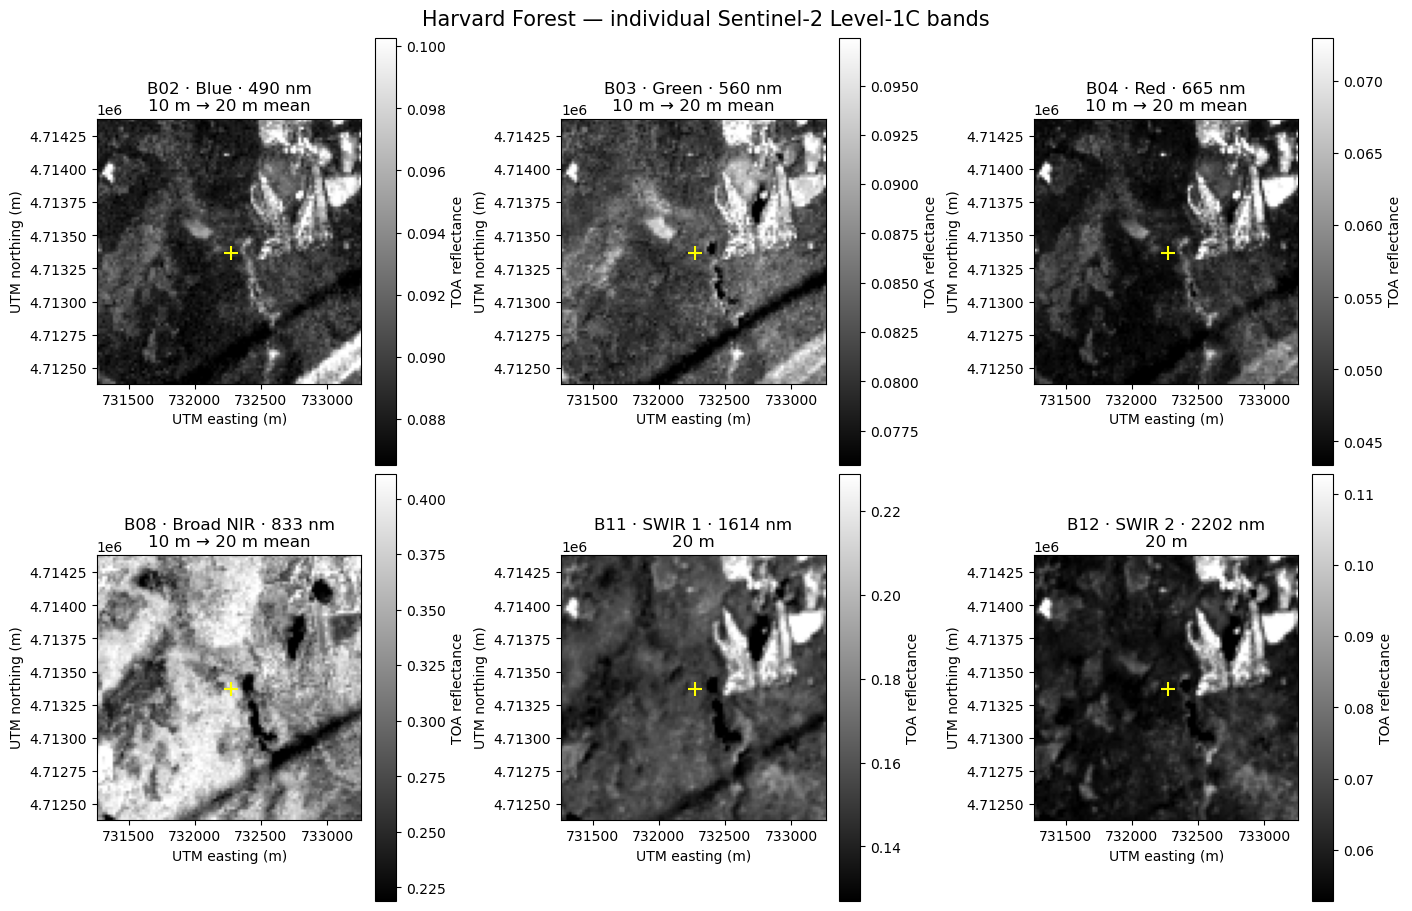

In [5]:
extent = (bounds.left, bounds.right, bounds.bottom, bounds.top)
tower_lon, tower_lat = -72.1715, 42.5378
tower_x, tower_y = transform("EPSG:4326", chip_crs, [tower_lon], [tower_lat])
tower_x, tower_y = tower_x[0], tower_y[0]

fig, axes = plt.subplots(2, 3, figsize=(14, 9), constrained_layout=True)
for ax, band in zip(axes.flat, band_order):
    image = toa[band]
    low, high = np.nanpercentile(image, (2, 98))
    artist = ax.imshow(
        image,
        extent=extent,
        origin="upper",
        cmap="gray",
        vmin=low,
        vmax=high,
    )
    ax.scatter(tower_x, tower_y, marker="+", color="yellow", edgecolor="black", s=90)
    ax.set_title(
        f'{band} · {bands[band]["name"]} · {bands[band]["wavelength_nm"]} nm\n'
        f'{bands[band]["resolution"]}'
    )
    ax.set_xlabel("UTM easting (m)")
    ax.set_ylabel("UTM northing (m)")
    fig.colorbar(artist, ax=ax, label="TOA reflectance")
fig.suptitle("Harvard Forest — individual Sentinel-2 Level-1C bands", fontsize=15)
plt.show()

## Natural-color RGB

B04/B03/B02 are assigned to red/green/blue. The composite shows the visible
landscape around the tower, marked with a yellow cross. A per-channel
percentile stretch and gamma adjustment make it easier to see on screen;
they are display operations, not additional reflectance corrections.

/tmp/ipykernel_1524476/3458141080.py:7: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(tower_x, tower_y, marker="+", color="yellow", edgecolor="black", s=110)


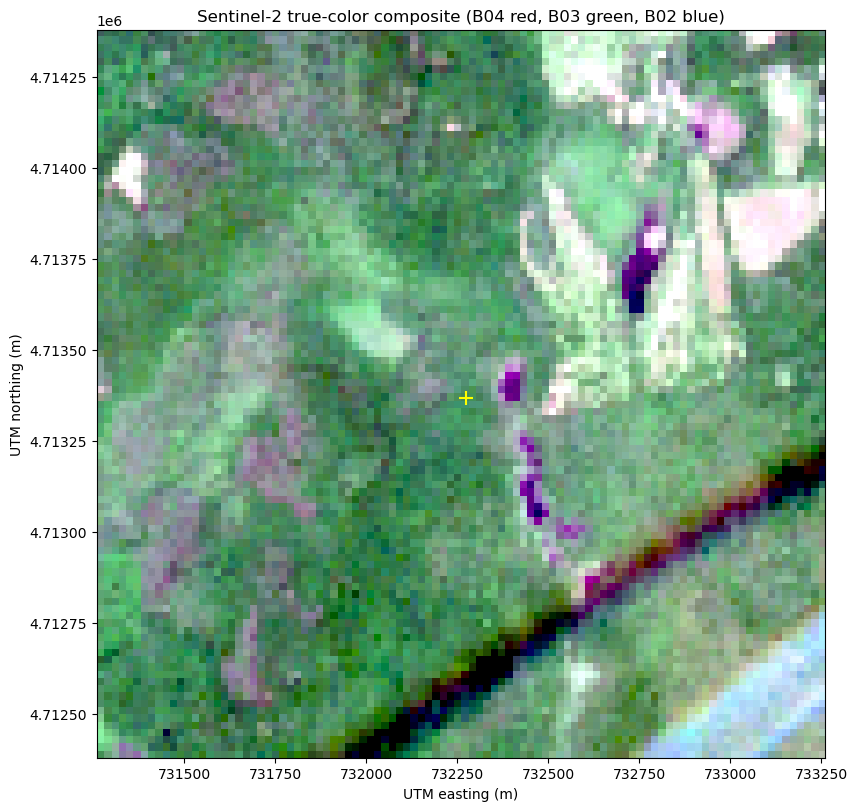

In [6]:
rgb = np.stack([toa[band] for band in ("B04", "B03", "B02")], axis=-1)
low, high = np.nanpercentile(rgb, (2, 98), axis=(0, 1))
rgb_display = np.clip((rgb - low) / (high - low), 0, 1) ** (1 / 2.2)

fig, ax = plt.subplots(figsize=(9, 8), constrained_layout=True)
ax.imshow(rgb_display, extent=extent, origin="upper")
ax.scatter(tower_x, tower_y, marker="+", color="yellow", edgecolor="black", s=110)
ax.set_title("Sentinel-2 true-color composite (B04 red, B03 green, B02 blue)")
ax.set_xlabel("UTM easting (m)")
ax.set_ylabel("UTM northing (m)")
plt.show()

**Interpretation:** This is a 2 km view centered on the tower, not a
classification or a cloud-free guarantee. Level-1C values describe
top-of-atmosphere reflectance. The NIR and SWIR channels complement visible
color because vegetation reflects strongly in NIR while water content and
vegetation structure influence the SWIR response.

## Obtaining a different source scene

To work with another date or location, use the
[Copernicus Browser](https://browser.dataspace.copernicus.eu/): sign in with
a Copernicus Data Space account, search for the area and acquisition date,
select **Sentinel-2 → Level-1C**, and choose a scene with suitable cloud
cover. Download the product (or the required tile and bands) as a SAFE
product. Its `MTD_MSIL1C.xml` metadata supplies the quantification value,
band-specific `RADIO_ADD_OFFSET` values, and special DN values. Keep the
processing level and the matching metadata together; Level-2A uses BOA
offsets and should not be decoded using the Level-1C formula above.

For a direct public band URL, such as the B04 link above, use
`wget -O B04.jp2 'BAND_URL'`. This downloads the entire band file.

Contains modified Copernicus Sentinel data (2023).